# Try a better method than the default IoU fusion

In [1]:
import sys
sys.path.append("../")

from src.fusion import *
import cv2

from local_files.segmentation_pipeline import instance_segmentation_pipeline as segment
from src.model_run import start_prediction_machine
from src.classifier import load_classifiers, Category_Classifier

from sklearn.base import TransformerMixin, BaseEstimator
class SelectColumns(BaseEstimator, TransformerMixin):
    def __init__(self, columns):
        self.columns = columns
    def fit(self, xs, ys, **params):
        return self
    def transform(self, xs):
        return xs[self.columns]

/home/trist/projects/DAAD_Tristan_Bioinformatics_2026/py3.11_venv/lib/python3.11/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/home/trist/projects/DAAD_Tristan_Bioinformatics_2026/py3.11_venv/lib/python3.11/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/home/trist/projects/DAAD_Tristan_Bioinformatics_2026/py3.11_venv/lib/python3.11/site-packages/detectron2/model_zoo/model_zoo.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [2]:
# Config cell
tangled = False

# SELECT MODEL
model_path = "/home/trist/projects/models/detectron_models/model2.5_at_end_of_tristans_internship.pth"

# CLASSIFIERS
bmp_cls = "/home/trist/projects/models/classifiers/bumps_embedded_classifier.pkl"
bg_cls = "/home/trist/projects/models/classifiers/bg_regular_classifier.pkl"

# detectron2
detectron_confidence_threshold = 0.0
fusion_iou_threshold = 0.1
epsilon = 0.0 


In [3]:
# predictor is the segmentaion model as a variable
predictor = start_prediction_machine(path_to_model=model_path, multi_class=False)

# Make the classifier class
bmp_predictor, bg_predictor = load_classifiers(bmp_cls, bg_cls)
classifier = Category_Classifier(None, None, None, None, bmp_predictor, bg_predictor, tangled)

/home/trist/projects/DAAD_Tristan_Bioinformatics_2026/py3.11_venv/lib/python3.11/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator MinMaxScaler from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/home/trist/projects/DAAD_Tristan_Bioinformatics_2026/py3.11_venv/lib/python3.11/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator DecisionTreeClassifier from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/home/trist/projects/DAAD_Tristan_Bioinformatics_2026/py3.11_venv/lib/python3.11/site-packages/skl

# previous method:

In [4]:
# one from poster
img_path = "/home/trist/projects/Annotated_dataset/20240926_N4_Plate1_DAG6_1000_L/000013.tif"


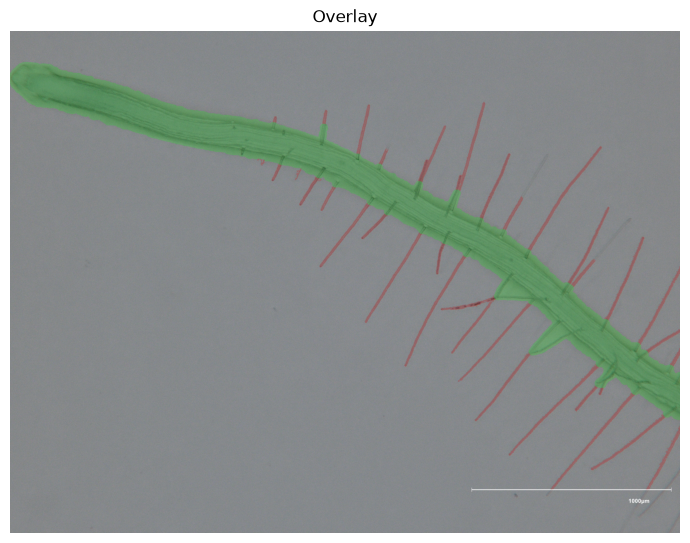

/home/trist/projects/DAAD_Tristan_Bioinformatics_2026/py3.11_venv/lib/python3.11/site-packages/torch/functional.py:504: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/native/TensorShape.cpp:4207.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
W1110 01:19:22.901000 72942 torch/fx/_symbolic_trace.py:57] is_fx_tracing will return true for both fx.symbolic_trace and torch.export. Please use is_fx_tracing_symbolic_tracing() for specifically fx.symbolic_trace or torch.compiler.is_compiling() for specifically torch.export/compile.


In [6]:
classified_instances, model_instances, classic_masks = segment(img_path,
                                                                predictor,
                                                                classifier,
                                                                fusion_iou_threshold = fusion_iou_threshold,
                                                                max_hole_size=20000,
                                                                show_overlay=True) 

In [7]:
model_dict = load_model_instances(model_instances, detectron_confidence_threshold=detectron_confidence_threshold)

model_masks = model_dict["masks"]

In [8]:
fused_masks = []
for item in classified_instances:
    if item["category_id"] != 0:
        fused_masks.append(item["mask"])

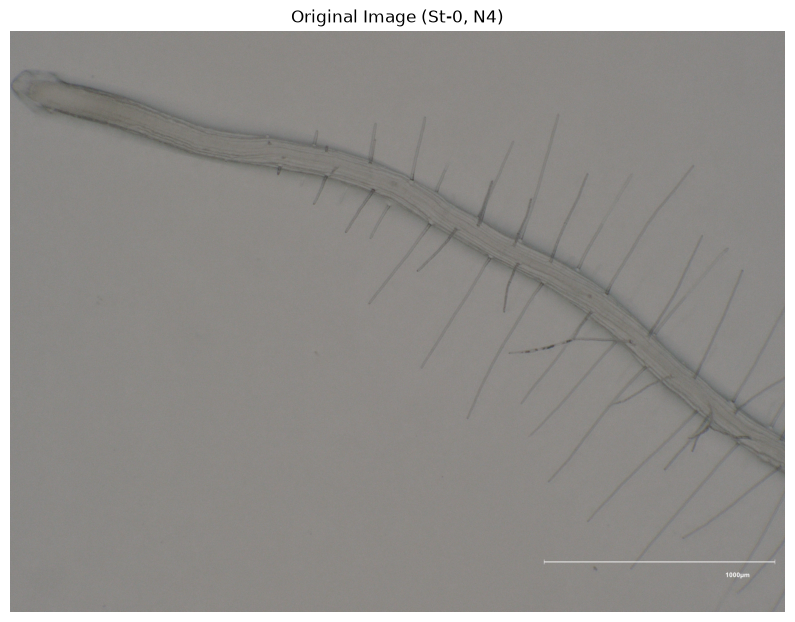

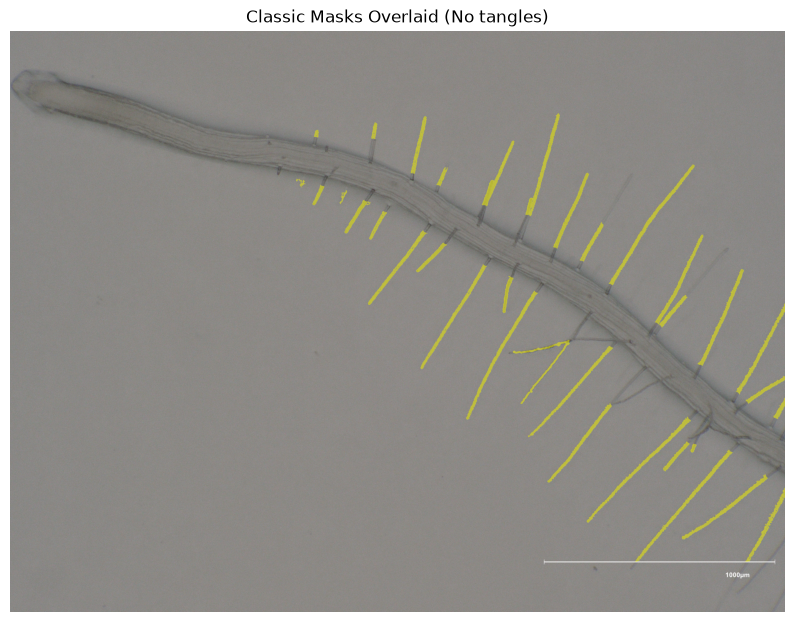

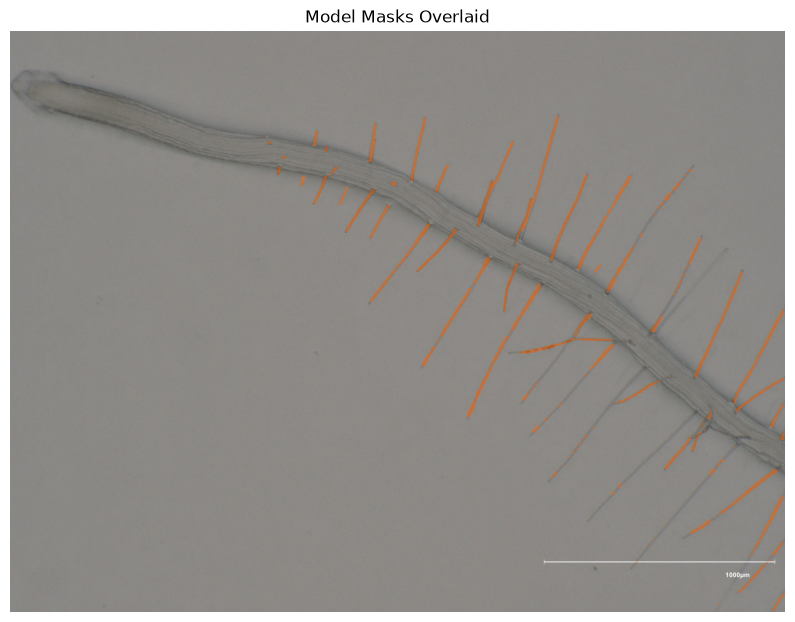

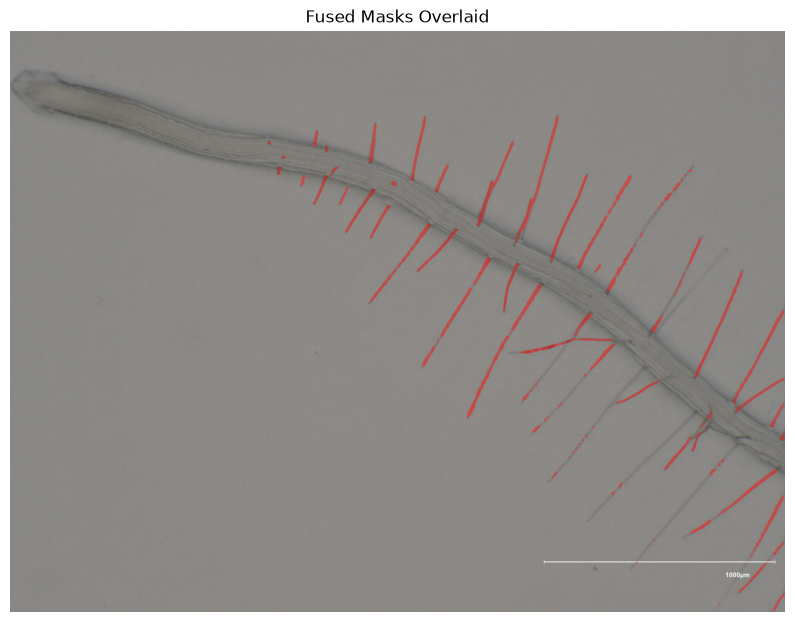

In [9]:
COLOURS = {"yellow": [255, 255, 0],
           "orange": [255, 100, 0],
           "red": [255, 25, 25],
           "turquoise": [0, 255, 255]}

# function to iterate through a list of boolean masks and overlay them 
def overlay_image(img_path, masklist, title, colour=[255, 165, 0]):
    image = cv2.imread(img_path)
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    overlay = image_rgb.copy()
    orange = np.array(colour, dtype=np.uint8)

    for mask in masklist:
        overlay[mask.astype(bool)] = orange

    alpha = 0.5  # blend strength
    blended = cv2.addWeighted(overlay, alpha, image_rgb, 1 - alpha, 0)

    plt.figure(figsize=(10, 8))
    plt.imshow(blended)
    plt.axis("off")
    plt.title(title)
    # plt.savefig(f"plots_for_poster/{title}.png", dpi=300, bbox_inches='tight')  # save FIRST
    plt.show()

overlay_image(img_path, [], "Original Image (St-0, N4)", colour=COLOURS["yellow"])
overlay_image(img_path, classic_masks, "Classic Masks Overlaid (No tangles)", colour=COLOURS["yellow"])
overlay_image(img_path, model_masks, "Model Masks Overlaid", colour=COLOURS["orange"])
overlay_image(img_path, model_masks, "Fused Masks Overlaid", colour=COLOURS["red"])